# Using the template

$P_{MG}/P_{GR} - 1$ for Horndeski models, without running hi_class. You only choose the gravity model $(c_K, c_B)$ and the background $(w_0, w_a)$. The rest of the cosmology and the coefficients come with the package.

```bash
pip install "git+https://github.com/JoseCDS17/Fitting_hi_class.git#subdirectory=template"
pip install matplotlib   # only for the figures of this notebook
```

The template was fitted for $10^3 \leq c_K \leq 10^6$ and $0.5 \leq c_B \leq 1.5$, at $z = 0$, with `propto_omega` ($\alpha_K = c_K \Omega_{DE}$, $\alpha_B = c_B \Omega_{DE}$). See the README for its accuracy and range of validity.

In [15]:
import shutil

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize

from horndeski_template import GlobalTemplate

# LaTeX fonts if LaTeX is installed, default matplotlib style otherwise
if shutil.which('latex') and shutil.which('dvipng'):
    plt.rcParams.update({'text.usetex': True, 'font.family': 'CM Roman', 'font.size': 12})

template = GlobalTemplate.default()

k = np.logspace(-3, 1, 200)   # h/Mpc

deviation_label = r'Deviation [$\%$]'

## 1. One model on $\Lambda$CDM

`template(k, ck, cb, w0, wa)` returns the deviation at each $k$. To get $P_{MG}$, multiply your GR spectrum by `1 + y`. The figures show the deviation in percent, `100 * y`.

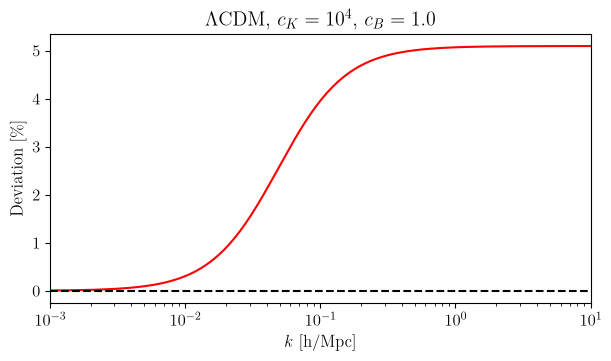

In [21]:
ck, cb = 1e4, 1.0
y = 100 * template(k, ck, cb, w0=-1, wa=0)   # percent

fig, ax = plt.subplots(figsize=(6, 3.5), layout='constrained')
ax.semilogx(k, y, color='r', linestyle='-')
ax.axhline(0, color='k', linestyle='--')
ax.set_xlim(k[0], k[-1])
ax.set_xlabel(r'$k$ [h/Mpc]')
ax.set_ylabel(deviation_label)
ax.set_title(rf'$\Lambda$CDM, $c_K = 10^{{{np.log10(ck):.0f}}}$, $c_B = {cb}$')
plt.show()

## 2. Sweep over $c_K$ and $c_B$

$c_B$ sets the height of the step. Both $c_K$ and $c_B$ move its position, through the braiding scale $k_B \propto \sqrt{c_K}/c_B$.

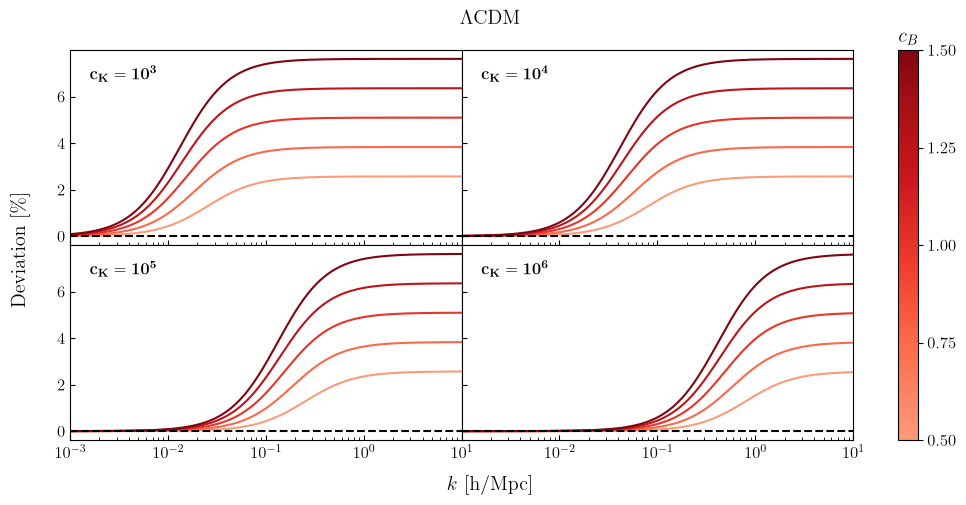

In [19]:
cK = np.logspace(3, 6, 4)
cB = np.linspace(0.5, 1.5, 5)
cB_norm = Normalize(cB[0], cB[-1])
cB_cmap = LinearSegmentedColormap.from_list('cB', plt.cm.Reds(np.linspace(0.35, 0.95, 256)))

fig, axs = plt.subplots(2, 2, figsize=(10, 5), sharex='col', sharey=True)
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.12, top=0.9, hspace=0, wspace=0)

for ax, ck in zip(axs.flat, cK):
    for cb in cB:
        ax.semilogx(k, 100 * template(k, ck, cb, w0=-1, wa=0), color=cB_cmap(cB_norm(cb)))
    ax.axhline(0, color='k', linestyle='--')
    ax.text(0.05, 0.85, rf'$\mathbf{{c_K=10^{{{np.log10(ck):.0f}}}}}$', transform=ax.transAxes)
    ax.tick_params(axis='both', which='both', direction='in')

for ax in axs[1]:
    ax.set_xlim(k[0], k[-1])
axs[1, 1].set_xticks(10.0**np.arange(-2, 2))   # avoid the 10^1 and 10^-3 labels touching
axs[0, 0].set_yticks([0, 2, 4, 6])
fig.supxlabel(r'$k$ [h/Mpc]')
fig.supylabel(deviation_label)
fig.suptitle(r'$\Lambda$CDM')

cbar = fig.colorbar(ScalarMappable(cB_norm, cB_cmap), ax=axs, ticks=cB, fraction=0.08)
cbar.ax.set_title(r'$c_B$')
plt.show()

## 3. From $\Lambda$CDM to the DESI background

Four backgrounds on the straight line that joins $\Lambda$CDM $(-1, 0)$ with the DESI DR2 preferred values $(-0.82, -0.65)$. Away from $\Lambda$CDM the large-scale level $L = \ell_1 (1 + w_0) + \ell_2 w_a$ is no longer zero, and it does not depend on $c_B$.

In [ ]:
ck = 1e4
w0_ref, wa_ref = -0.82, -0.65
w0_line = np.linspace(-1, w0_ref, 4)
wa_line = np.linspace(0, wa_ref, 4)

fig, axs = plt.subplots(2, 2, figsize=(10, 5), sharex='col', sharey=True)
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.12, top=0.9, hspace=0, wspace=0)

for ax, w0, wa in zip(axs.flat, w0_line, wa_line):
    for cb in cB:
        ax.semilogx(k, 100 * template(k, ck, cb, w0, wa), color=cB_cmap(cB_norm(cb)))
    ax.axhline(0, color='k', linestyle='--')
    ax.text(0.05, 0.93, rf'$\mathbf{{w_0={w0:.2f}}}$' + '\n' + rf'$\mathbf{{w_a={wa:.2f}}}$',
            transform=ax.transAxes, va='top')
    ax.tick_params(axis='both', which='both', direction='in')

for ax in axs[1]:
    ax.set_xlim(k[0], k[-1])
axs[1, 1].set_xticks(10.0**np.arange(-2, 2))   # avoid the 10^1 and 10^-3 labels touching
axs[0, 0].set_yticks([0, 2, 4, 6])
fig.supxlabel(r'$k$ [h/Mpc]')
fig.supylabel(deviation_label)
fig.suptitle(rf'$c_K = 10^{{{np.log10(ck):.0f}}}$')

cbar = fig.colorbar(ScalarMappable(cB_norm, cB_cmap), ax=axs, ticks=cB, fraction=0.08)
cbar.ax.set_title(r'$c_B$')
plt.show()